In [ ]:
   !pip -q install -U ultralytics

In [ ]:
import os, re, json, random, shutil, math, time, platform, warnings
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster

try:
    import torch
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

warnings.filterwarnings("ignore")
os.environ["WANDB_MODE"] = "disabled"
os.environ["COMET_MODE"] = "disabled"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    if HAS_TORCH:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
seed_everything()

HAS_GPU = HAS_TORCH and torch.cuda.is_available()
print("Python :", platform.python_version())
print("OpenCV :", cv2.__version__)
if HAS_TORCH:
    print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "TIDAK ADA")
if HAS_TORCH and not HAS_GPU:
    print("PERINGATAN: GPU tidak terdeteksi. Training pada CPU tidak realistis untuk dataset ini.")

Python : 3.13.16
OpenCV : 4.14.0
PyTorch: 2.11.0+cu130 | GPU: Tesla T4


In [ ]:
CFG = dict(
    DATASET_HINT  = "detrac",
    DATA_ROOT     = None,

    # Definisi kelas
    HEAVY_CLASSES = ["bus", "others"],
    CLASS_MODE    = "heavy_binary",

    # Pengambilan frame
    STRIDE_TRAIN       = 5,
    STRIDE_TRAIN_HEAVY = 2,
    STRIDE_VAL         = 10,
    STRIDE_TEST        = 5,

    # Pembagian data
    VAL_FRACTION_SEQ   = 0.20,
    TEST_FRACTION_SEQ  = 0.20,
    LOC_DIST_THRESH    = 0.55,
    SPLIT_TRIALS       = 4000,

    # Pembersihan label
    MIN_BOX_PX         = 3,
    IGNORE_FRAC_DROP   = 0.5,
    FILL_VALUE         = 114,

    # Training
    MODEL    = "yolo11m.pt",
    IMGSZ    = 960,
    EPOCHS   = 15,
    PATIENCE = 10,
    CLOSE_MOSAIC = 3,
    TIME_HOURS = None,
    BATCH    = 16,
    WORKERS  = 4,
    DEVICE   = "0",
    RESUME   = False,
    EXPORT_ONNX = False,
)

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
WORK.mkdir(parents=True, exist_ok=True)
YOLO_DIR = (Path("/kaggle/temp") / "yolo_data") if Path("/kaggle/temp").exists() else (WORK / "yolo_data")
RUNS_DIR = WORK / "runs"
OUT_DIR  = WORK / "hasil"
for d in (YOLO_DIR, RUNS_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Folder kerja:", WORK.resolve())

Folder kerja: /kaggle/working


### 1. Dataset UA-DETRAC

In [ ]:
if CFG["DATA_ROOT"] is None:
    KIN = Path("/kaggle/input")
    assert KIN.exists(), "/kaggle/input tidak ada. Pastikan ini berjalan di Kaggle, atau isi CFG['DATA_ROOT'] manual."
    # cari folder (kedalaman <= 3) yang namanya memuat kata kunci dataset
    cands = [p for p in KIN.glob("*") if p.is_dir()] + [p for p in KIN.glob("*/*") if p.is_dir()] + [p for p in KIN.glob("*/*/*") if p.is_dir()]
    hits = [p for p in cands if CFG["DATASET_HINT"] in p.name.lower()]
    if hits:
        DATA_ROOT = sorted(hits, key=lambda p: len(p.parts))[0]
    else:
        DATA_ROOT = KIN
        print("PERINGATAN: folder dataset tidak ditemukan lewat nama; memindai seluruh /kaggle/input.")
        print("Isi /kaggle/input:", [p.name for p in KIN.iterdir()])
else:
    DATA_ROOT = Path(CFG["DATA_ROOT"])
print("DATA_ROOT:", DATA_ROOT)
assert DATA_ROOT.exists(), "DATA_ROOT tidak ditemukan"

DATA_ROOT: /kaggle/input/datasets/bratjay/ua-detrac-orig


In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png"}

# --- ringkasan isi
ext_counter = Counter()
for dp, dn, fn in os.walk(DATA_ROOT):
    for f in fn:
        ext_counter[Path(f).suffix.lower()] += 1
print("Jumlah file per ekstensi:", dict(ext_counter.most_common()))

def show_tree(root, depth=0, max_depth=2, max_items=6):
    items = sorted(root.iterdir(), key=lambda p: (p.is_file(), p.name))
    dirs  = [p for p in items if p.is_dir()]
    files = [p for p in items if p.is_file()]
    for p in dirs[:max_items]:
        n_files = sum(1 for _ in p.iterdir()) if p.is_dir() else 0
        print("  " * depth + f"[D] {p.name}  ({n_files} entri)")
        if depth + 1 < max_depth:
            show_tree(p, depth + 1, max_depth, max_items)
    if len(dirs) > max_items:
        print("  " * depth + f"... +{len(dirs) - max_items} folder lain")
    for p in files[:max_items]:
        print("  " * depth + f"[F] {p.name}")
    if len(files) > max_items:
        print("  " * depth + f"... +{len(files) - max_items} file lain")
show_tree(DATA_ROOT, max_depth=3)

Jumlah file per ekstensi: {'.jpg': 140131, '.m': 573, '.txt': 131, '.xml': 100, '.png': 16, '.mexa64': 10, '.mexmaci': 10, '.mexmaci64': 10, '.mexw32': 10, '.mexw64': 10, '.dll': 10, '.c': 9, '.exe': 6, '.mat': 6, '.md': 2, '.html': 2, '.pdb': 2, '.cpp': 1}
[D] DETRAC-Images  (1 entri)
  [D] DETRAC-Images  (100 entri)
    [D] MVI_20011  (664 entri)
    [D] MVI_20012  (936 entri)
    [D] MVI_20032  (437 entri)
    [D] MVI_20033  (784 entri)
    [D] MVI_20034  (800 entri)
    [D] MVI_20035  (800 entri)
    ... +94 folder lain
[D] DETRAC-MOT-toolkit  (1 entri)
  [D] DETRAC-MOT-toolkit  (10 entri)
    [D] evaluation  (30 entri)
    [D] trackers  (8 entri)
    [D] utils  (14 entri)
    [F] DETRAC_experiment.m
    [F] README.md
    [F] initialize_environment.m
    [F] load_datasets.m
    [F] run_experiment.m
    [F] sequences.txt
    ... +1 file lain
[D] DETRAC-Test-Annotations-XML  (1 entri)
  [D] DETRAC-Test-Annotations-XML  (40 entri)
    [F] MVI_39031.xml
    [F] MVI_39051.xml
    [F] MV

### 2. Parsing Anotasi
Kode mencari file XML UA-DETRAC, mencocokkan setiap sekuens dengan folder frame, lalu membaca anotasi kendaraan, bounding box, atribut cuaca, dan region yang diabaikan.

In [ ]:
def peek_root(p):
    try:
        for _, el in ET.iterparse(p, events=("start",)):
            return el.tag, dict(el.attrib)
    except ET.ParseError:
        return None, {}
    return None, {}

def official_split_of(p):
    s = " ".join(x.lower() for x in p.relative_to(DATA_ROOT).parts)
    if "test" in s:
        return "test"
    if "train" in s:
        return "train"
    return "unknown"

seq_xml, seq_official = {}, {}
for p in sorted(DATA_ROOT.rglob("*.xml")):
    tag, attr = peek_root(p)
    if tag == "sequence" and attr.get("name"):
        seq_xml[attr["name"]] = p
        seq_official[attr["name"]] = official_split_of(p)

print(f"XML anotasi DETRAC ditemukan: {len(seq_xml)} sekuens")
print("Per split resmi:", dict(Counter(seq_official.values())))
if not seq_xml:
    raise RuntimeError(
        "Tidak ada XML berformat DETRAC (<sequence name=...>) di dataset ini. "
        "Lihat pohon folder di sel sebelumnya; format anotasi harus dicek dulu "
        "(mis. MOT .txt atau .mat) dan sel parsing di Langkah 4 disesuaikan.")

seq_dir = {}
for dp, dn, fn in os.walk(DATA_ROOT):
    name = Path(dp).name
    if name in seq_xml and any(Path(f).suffix.lower() in IMG_EXT for f in fn):
        seq_dir[name] = Path(dp)

no_img = sorted(set(seq_xml) - set(seq_dir))
print(f"Sekuens dengan folder gambar: {len(seq_dir)} | tanpa gambar: {len(no_img)}")
if no_img:
    print("  Tanpa gambar (dikeluarkan dari proses):", no_img[:10], "..." if len(no_img) > 10 else "")
def build_frame_map(d):
    m = {}
    for f in d.iterdir():
        if f.suffix.lower() in IMG_EXT:
            nums = re.findall(r"\d+", f.stem)
            if nums:
                m[int(nums[-1])] = f
    return m

frame_maps = {s: build_frame_map(d) for s, d in seq_dir.items()}
usable_seqs = sorted(seq_dir)
print("Contoh sekuens:", usable_seqs[:3], "| contoh nama file:", next(iter(frame_maps[usable_seqs[0]].values())).name)

XML anotasi DETRAC ditemukan: 100 sekuens
Per split resmi: {'test': 40, 'train': 60}
Sekuens dengan folder gambar: 100 | tanpa gambar: 0
Contoh sekuens: ['MVI_20011', 'MVI_20012', 'MVI_20032'] | contoh nama file: img00001.jpg


In [ ]:
def parse_sequence_xml(path):
    root = ET.parse(path).getroot()
    name = root.get("name")
    sa = root.find("sequence_attribute")
    weather = None
    cam_state = None
    if sa is not None:
        weather = sa.get("sence_weather") or sa.get("scene_weather") or sa.get("weather")
        cam_state = sa.get("camera_state")

    ignored = []
    for b in root.findall("ignored_region/box"):
        ignored.append((float(b.get("left")), float(b.get("top")), float(b.get("width")), float(b.get("height"))))

    box_rows, frame_rows = [], []
    for fr in root.findall("frame"):
        num = int(fr.get("num"))
        targets = fr.findall("target_list/target")
        frame_rows.append((name, num, len(targets)))
        for t in targets:
            b = t.find("box")
            a = t.find("attribute")
            if b is None or a is None or a.get("vehicle_type") is None:
                raise ValueError(f"{name} frame {num}: target tanpa <box>/<attribute vehicle_type>")
            occ = t.find("occlusion")
            n_occ = len(occ.findall("region_overlap")) if occ is not None else 0
            box_rows.append(dict(
                seq=name, frame=num, target_id=int(t.get("id")),
                left=float(b.get("left")), top=float(b.get("top")),
                w=float(b.get("width")), h=float(b.get("height")),
                vehicle_type=a.get("vehicle_type").strip().lower(),
                truncation=float(a.get("truncation_ratio", 0) or 0),
                n_occluders=n_occ))
    meta = dict(seq=name, weather=(weather or "unknown").strip().lower(), camera_state=cam_state,
                n_ignored=len(ignored), ignored=ignored)
    return box_rows, frame_rows, meta

all_boxes, all_frames, all_meta = [], [], []
for s in usable_seqs:
    b, f, m = parse_sequence_xml(seq_xml[s])
    all_boxes += b; all_frames += f; all_meta.append(m)

boxes_df  = pd.DataFrame(all_boxes)
frames_df = pd.DataFrame(all_frames, columns=["seq", "frame", "n_targets"])
meta_df   = pd.DataFrame(all_meta).set_index("seq")
ignored_by_seq = meta_df["ignored"].to_dict()

# hanya frame yang gambarnya benar-benar ada
frames_df["has_image"] = [fr in frame_maps[s] for s, fr in zip(frames_df.seq, frames_df.frame)]
missing_img = (~frames_df.has_image).sum()
print(f"Frame di XML: {len(frames_df)} | tanpa file gambar: {missing_img}")
frames_df = frames_df[frames_df.has_image].reset_index(drop=True)
boxes_df  = boxes_df.merge(frames_df[["seq", "frame"]], on=["seq", "frame"], how="inner").reset_index(drop=True)

print(f"Total kotak: {len(boxes_df):,} | sekuens: {boxes_df.seq.nunique()}")
print("Jenis kendaraan yang ada:", dict(Counter(boxes_df.vehicle_type)))
boxes_df.head()

Frame di XML: 138252 | tanpa file gambar: 0
Total kotak: 1,274,055 | sekuens: 100
Jenis kendaraan yang ada: {'car': 1052408, 'van': 95570, 'others': 20641, 'bus': 105436}


,seq,frame,target_id,left,top,w,h,vehicle_type,truncation,n_occluders
0,MVI_20011,1,1,592.75,378.800,160.05,162.200,car,0.1,0
1,MVI_20011,1,2,557.65,120.980,47.20,43.060,car,0.0,0
2,MVI_20011,1,3,545.20,88.270,35.25,30.080,car,0.0,1
3,MVI_20011,1,4,508.35,67.500,28.00,25.925,car,0.0,0
4,MVI_20011,1,5,553.00,70.095,29.55,19.695,car,0.0,0


In [ ]:
# 1) Ukuran gambar per sekuens
sizes = {}
for s in usable_seqs:
    img = cv2.imread(str(next(iter(frame_maps[s].values()))))
    sizes[s] = (img.shape[1], img.shape[0])      # (W, H)
print("Ukuran gambar (W,H) yang muncul:", dict(Counter(sizes.values())))
IMG_W, IMG_H = Counter(sizes.values()).most_common(1)[0][0]

# 2) Tabel tingkat sekuens
seq_df = meta_df.drop(columns=["ignored"]).copy()
seq_df["official"] = pd.Series(seq_official)
seq_df["n_frames"] = frames_df.groupby("seq").size()
seq_df["n_boxes"]  = boxes_df.groupby("seq").size()
seq_df["n_heavy"]  = boxes_df[boxes_df.vehicle_type.isin(CFG["HEAVY_CLASSES"])].groupby("seq").size()
seq_df["n_heavy"]  = seq_df["n_heavy"].fillna(0).astype(int)
seq_df["ignored_area_frac"] = [
    min(1.0, sum(w * h for _, _, w, h in ignored_by_seq[s]) / (IMG_W * IMG_H)) for s in seq_df.index]
display(seq_df.sort_index().head(10))
print(seq_df.groupby("official")[["n_frames", "n_boxes", "n_heavy"]].sum())

Ukuran gambar (W,H) yang muncul: {(960, 540): 100}


,weather,camera_state,n_ignored,official,n_frames,n_boxes,n_heavy,ignored_area_frac
seq,,,,,,,,
MVI_20011,sunny,unstable,7,train,664,7655,306,0.151002
MVI_20012,sunny,unstable,6,train,936,8608,1337,0.124890
MVI_20032,sunny,unstable,5,train,437,1657,0,0.115695
MVI_20033,sunny,unstable,5,train,784,5274,327,0.139917
MVI_20034,sunny,unstable,5,train,800,9934,1373,0.131552
MVI_20035,sunny,unstable,7,train,800,11855,0,0.134046
MVI_20051,sunny,unstable,5,train,906,8934,906,0.125394
MVI_20052,sunny,unstable,6,train,694,8359,694,0.119527
MVI_20061,sunny,unstable,6,train,800,9256,873,0.202157


          n_frames  n_boxes  n_heavy
official                            
test         56167   675774    88700
train        82085   598281    37377


Jumlah kotak per jenis kendaraan:


official,test,train,All
vehicle_type,,,
bus,71785,33651,105436
car,548555,503853,1052408
others,16915,3726,20641
van,38519,57051,95570
All,675774,598281,1274055


Persentase per kolom:


official,test,train
vehicle_type,,
bus,10.62,5.62
car,81.17,84.22
others,2.50,0.62
van,5.70,9.54


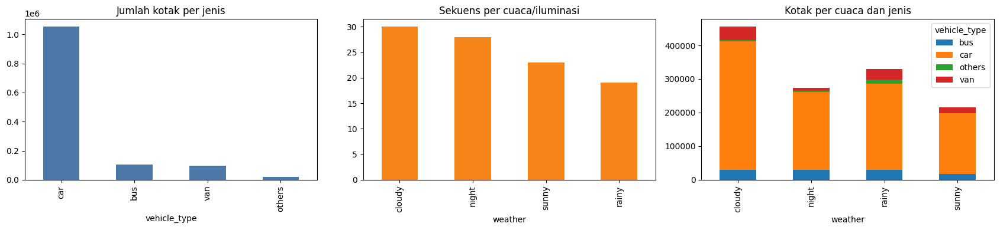

Porsi kendaraan berat (['bus', 'others']) dari semua kotak: 9.90%


In [ ]:
# 3) Sebaran kelas
b = boxes_df.merge(seq_df[["official", "weather"]], left_on="seq", right_index=True)
tab = pd.crosstab(b.vehicle_type, b.official, margins=True)
tab_pct = (pd.crosstab(b.vehicle_type, b.official, normalize="columns") * 100).round(2)
print("Jumlah kotak per jenis kendaraan:"); display(tab)
print("Persentase per kolom:"); display(tab_pct)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
b.vehicle_type.value_counts().plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set_title("Jumlah kotak per jenis")
seq_df.weather.value_counts().plot.bar(ax=ax[1], color="#F58518"); ax[1].set_title("Sekuens per cuaca/iluminasi")
(b.groupby(["weather", "vehicle_type"]).size().unstack(fill_value=0)).plot.bar(stacked=True, ax=ax[2])
ax[2].set_title("Kotak per cuaca dan jenis"); plt.tight_layout(); plt.show()

heavy_share = b.vehicle_type.isin(CFG["HEAVY_CLASSES"]).mean() * 100
print(f"Porsi kendaraan berat ({CFG['HEAVY_CLASSES']}) dari semua kotak: {heavy_share:.2f}%")

scale_bin     kecil(<50)  sedang(50-150)  besar(>150)
vehicle_type                                         
bus                0.025           0.578        0.397
car                0.389           0.565        0.046
others             0.059           0.558        0.383
van                0.303           0.571        0.126


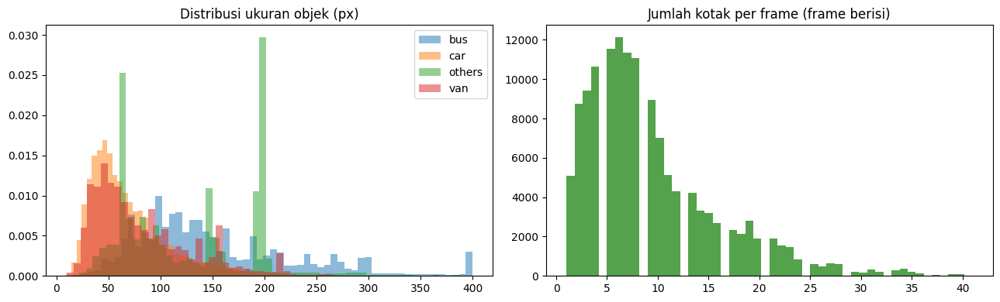

Frame tanpa target: 0 dari 138252


In [ ]:
# 4) Ukuran objek
b["scale"] = np.sqrt(b.w * b.h)
b["scale_bin"] = pd.cut(b.scale, [0, 50, 150, 1e9], labels=["kecil(<50)", "sedang(50-150)", "besar(>150)"])
print(pd.crosstab(b.vehicle_type, b.scale_bin, normalize="index").round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for t, g in b.groupby("vehicle_type"):
    ax[0].hist(np.clip(g.scale, 0, 400), bins=60, alpha=0.5, label=t, density=True)
ax[0].set_title("Distribusi ukuran objek (px)"); ax[0].legend()
bpf = boxes_df.groupby(["seq", "frame"]).size()
ax[1].hist(bpf, bins=50, color="#54A24B"); ax[1].set_title("Jumlah kotak per frame (frame berisi)")
plt.tight_layout(); plt.show()
print(f"Frame tanpa target: {(frames_df.n_targets == 0).sum()} dari {len(frames_df)}")

In [ ]:
# 5) Kualitas anotasi
bad_size = boxes_df[(boxes_df.w <= 0) | (boxes_df.h <= 0)]
x2 = boxes_df.left + boxes_df.w; y2 = boxes_df.top + boxes_df.h
out_of_img = boxes_df[(boxes_df.left < 0) | (boxes_df.top < 0) | (x2 > IMG_W) | (y2 > IMG_H)]
dups = boxes_df.duplicated(subset=["seq", "frame", "left", "top", "w", "h"]).sum()
dup_ids = boxes_df.duplicated(subset=["seq", "frame", "target_id"]).sum()
tiny = (np.sqrt(boxes_df.w * boxes_df.h) < CFG["MIN_BOX_PX"]).sum()
print(f"Kotak ukuran <=0 : {len(bad_size)}")
print(f"Kotak keluar batas gambar (akan dipotong): {len(out_of_img)} ({len(out_of_img)/len(boxes_df)*100:.2f}%)")
print(f"Kotak duplikat persis: {dups} | id target ganda di frame sama: {dup_ids}")
print(f"Kotak lebih kecil dari {CFG['MIN_BOX_PX']} px: {tiny}")

Kotak ukuran <=0 : 0
Kotak keluar batas gambar (akan dipotong): 130181 (10.22%)
Kotak duplikat persis: 0 | id target ganda di frame sama: 0
Kotak lebih kecil dari 3 px: 0


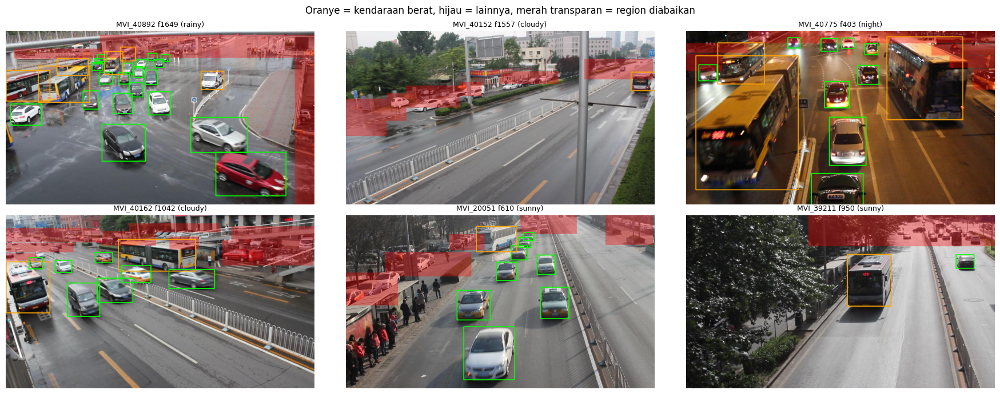

In [ ]:
def draw_gt(seq, frame, ax):
    img = cv2.cvtColor(cv2.imread(str(frame_maps[seq][frame])), cv2.COLOR_BGR2RGB)
    ov = img.copy()
    for (l, t, w, h) in ignored_by_seq[seq]:
        cv2.rectangle(ov, (int(l), int(t)), (int(l + w), int(t + h)), (255, 0, 0), -1)
    img = cv2.addWeighted(ov, 0.35, img, 0.65, 0)
    for r in boxes_df[(boxes_df.seq == seq) & (boxes_df.frame == frame)].itertuples():
        col = (255, 165, 0) if r.vehicle_type in CFG["HEAVY_CLASSES"] else (0, 255, 0)
        cv2.rectangle(img, (int(r.left), int(r.top)), (int(r.left + r.w), int(r.top + r.h)), col, 2)
    ax.imshow(img); ax.set_title(f"{seq} f{frame} ({seq_df.loc[seq, 'weather']})", fontsize=9); ax.axis("off")

heavy_frames = boxes_df[boxes_df.vehicle_type.isin(CFG["HEAVY_CLASSES"])][["seq", "frame"]].drop_duplicates()
sample = heavy_frames.sample(min(6, len(heavy_frames)), random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, (s, f) in zip(axes.ravel(), sample.itertuples(index=False)):
    draw_gt(s, f, ax)
plt.suptitle("Oranye = kendaraan berat, hijau = lainnya, merah transparan = region diabaikan"); plt.tight_layout(); plt.show()

### 3. Pemetaan Kelas
Jenis kendaraan pada anotasi dipetakan ke ID kelas YOLO. Pada mode `heavy_binary`, kelas bus dan others digabung menjadi satu kelas `heavy_vehicle`.

In [ ]:
HEAVY = set(CFG["HEAVY_CLASSES"])
observed_types = sorted(boxes_df.vehicle_type.unique())
missing_heavy = HEAVY - set(observed_types)
assert not missing_heavy, f"Jenis {missing_heavy} tidak ada di data. Jenis yang ada: {observed_types}"

if CFG["CLASS_MODE"] == "heavy_binary":
    CLASS_NAMES = ["heavy_vehicle"]
    TYPE2ID = {t: 0 for t in HEAVY}
elif CFG["CLASS_MODE"] == "four_class":
    order = [t for t in ["car", "van", "bus", "others"] if t in observed_types] + \
            [t for t in observed_types if t not in ["car", "van", "bus", "others"]]
    CLASS_NAMES = order
    TYPE2ID = {t: i for i, t in enumerate(order)}
else:
    raise ValueError("CLASS_MODE harus 'heavy_binary' atau 'four_class'")

HEAVY_IDS = sorted({TYPE2ID[t] for t in HEAVY})
print("Kelas YOLO :", dict(enumerate(CLASS_NAMES)))
print("Pemetaan   :", TYPE2ID)
print("Tidak dilabel (menjadi latar belakang):", sorted(set(observed_types) - set(TYPE2ID)))
print("ID kelas berat:", HEAVY_IDS)

boxes_df["cls"] = boxes_df.vehicle_type.map(TYPE2ID)
labeled_df = boxes_df.dropna(subset=["cls"]).copy()
labeled_df["cls"] = labeled_df["cls"].astype(int)
print(labeled_df.cls.map(dict(enumerate(CLASS_NAMES))).value_counts())

Kelas YOLO : {0: 'heavy_vehicle'}
Pemetaan   : {'others': 0, 'bus': 0}
Tidak dilabel (menjadi latar belakang): ['car', 'van']
ID kelas berat: [0]
cls
heavy_vehicle    126077
Name: count, dtype: int64


### 4. Pembagian Dataset
Kode mengelompokkan sekuens berdasarkan kemiripan lokasi kamera, kemudian membagi data menjadi train, validation, dan test.

100 sekuens -> 60 kelompok lokasi (paper: 24 lokasi untuk 100 video)
Ukuran kelompok: [5, 4, 4, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


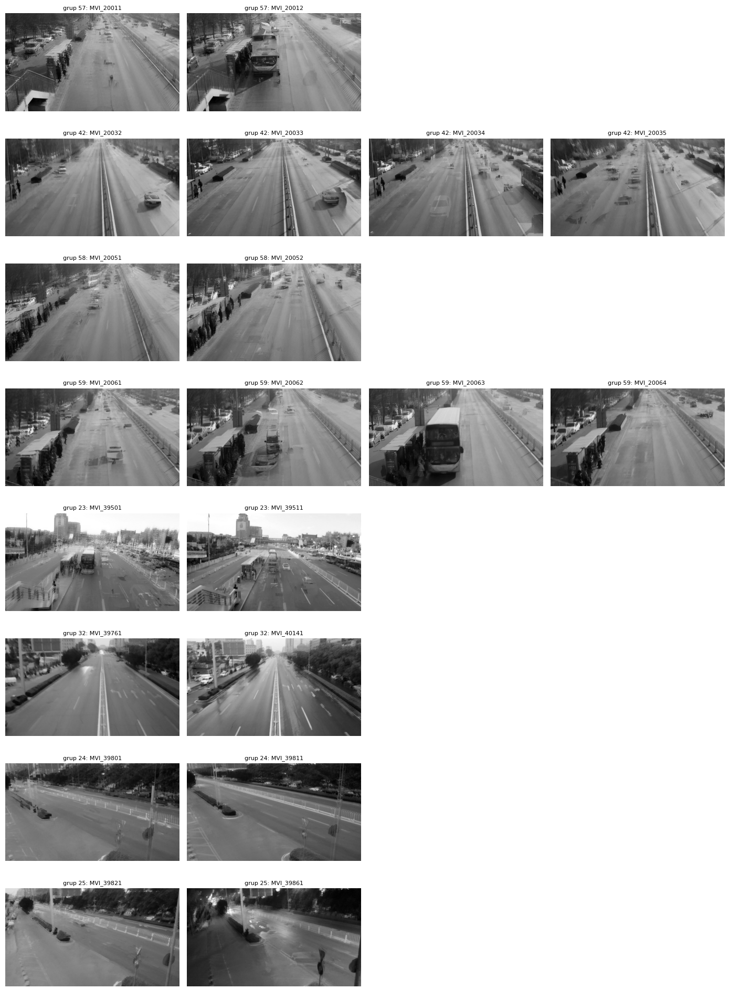

In [ ]:
def seq_signature(seq):
    nums = sorted(frame_maps[seq])
    pick = [nums[int(i)] for i in np.linspace(0, len(nums) - 1, 5)]
    imgs = [cv2.imread(str(frame_maps[seq][n]), cv2.IMREAD_GRAYSCALE) for n in pick]
    med = np.median(np.stack(imgs), 0).astype(np.uint8)
    t = cv2.resize(med, (64, 36), interpolation=cv2.INTER_AREA).astype(np.float32)
    t = cv2.GaussianBlur(t, (3, 3), 0)
    gx = cv2.Sobel(t, cv2.CV_32F, 1, 0); gy = cv2.Sobel(t, cv2.CV_32F, 0, 1)
    g = np.sqrt(gx ** 2 + gy ** 2).ravel()
    g = g - g.mean(); g = g / (g.std() + 1e-6)
    return g, med

sig, thumbs = {}, {}
for s in usable_seqs:
    sig[s], thumbs[s] = seq_signature(s)

M = np.stack([sig[s] for s in usable_seqs])
corr = np.corrcoef(M)
dist = 1 - corr
iu = np.triu_indices(len(usable_seqs), 1)
Z = linkage(dist[iu], method="average")
loc_id = fcluster(Z, t=CFG["LOC_DIST_THRESH"], criterion="distance")
seq_df["loc_group"] = pd.Series(dict(zip(usable_seqs, loc_id)))
print(f"{len(usable_seqs)} sekuens -> {seq_df.loc_group.nunique()} kelompok lokasi (paper: 24 lokasi untuk 100 video)")
print("Ukuran kelompok:", sorted(Counter(loc_id).values(), reverse=True))

# montase kelompok yang berisi >1 sekuens, untuk diperiksa mata
multi = [g for g, c in Counter(loc_id).items() if c > 1][:8]
if multi:
    fig, axes = plt.subplots(len(multi), 4, figsize=(14, 2.4 * len(multi)), squeeze=False)
    for r, g in enumerate(multi):
        members = [s for s in usable_seqs if seq_df.loc_group[s] == g][:4]
        for c in range(4):
            axes[r, c].axis("off")
            if c < len(members):
                axes[r, c].imshow(thumbs[members[c]], cmap="gray")
                axes[r, c].set_title(f"grup {g}: {members[c]}", fontsize=8)
    plt.tight_layout(); plt.show()

In [ ]:
def choose_groups(pool_df, frac, trials, rng):
    groups = {g: d.index.tolist() for g, d in pool_df.groupby("loc_group")}
    gids = list(groups)
    target_n = frac * len(pool_df)
    w_all = pool_df.weather.value_counts(normalize=True)
    h_all = pool_df.n_heavy.sum() / max(pool_df.n_boxes.sum(), 1)
    best, best_cost = None, 1e18
    for _ in range(trials):
        rng.shuffle(gids)
        chosen, n = [], 0
        for g in gids:
            if n >= target_n:
                break
            chosen.append(g); n += len(groups[g])
        sel = pool_df.loc[[s for g in chosen for s in groups[g]]]
        if sel.n_heavy.sum() == 0 or len(sel) == len(pool_df):
            continue
        w_sel = sel.weather.value_counts(normalize=True).reindex(w_all.index).fillna(0)
        h_sel = sel.n_heavy.sum() / max(sel.n_boxes.sum(), 1)
        cost = (abs(len(sel) - target_n) / len(pool_df)
                + (w_sel - w_all).abs().sum()
                + abs(h_sel - h_all) / max(h_all, 1e-9))
        if cost < best_cost:
            best, best_cost = list(sel.index), cost
    if best is None:
        raise RuntimeError("Tidak ada pembagian valid; periksa jumlah sekuens/kendaraan berat")
    return best, best_cost

rng = random.Random(SEED)
seq_df["split"] = None
official_test_seqs = seq_df.index[(seq_df.official == "test") & (seq_df.n_boxes > 0)].tolist()

if len(official_test_seqs) >= 5:
    seq_df.loc[official_test_seqs, "split"] = "test"
    print(f"Test = {len(official_test_seqs)} sekuens test resmi (lokasi berbeda dari train).")
    pool = seq_df[seq_df.split.isna()]
else:
    print("Anotasi test resmi tidak tersedia/terlalu sedikit -> test diambil dari data berlabel, per kelompok lokasi.")
    pool = seq_df.copy()
    test_seqs, c = choose_groups(pool, CFG["TEST_FRACTION_SEQ"], CFG["SPLIT_TRIALS"], rng)
    seq_df.loc[test_seqs, "split"] = "test"
    pool = seq_df[seq_df.split.isna()]

test_groups = set(seq_df.loc[seq_df.split == "test", "loc_group"])
leaky = pool[pool.loc_group.isin(test_groups)].index.tolist()
if leaky:
    print(f"{len(leaky)} sekuens train sekelompok lokasi dengan test -> dikeluarkan agar tidak bocor:", leaky[:8])
    seq_df.loc[leaky, "split"] = "dropped_leak"
    pool = seq_df[seq_df.split.isna()]

val_seqs, c = choose_groups(pool, CFG["VAL_FRACTION_SEQ"], CFG["SPLIT_TRIALS"], rng)
seq_df.loc[val_seqs, "split"] = "val"
seq_df.loc[seq_df.split.isna(), "split"] = "train"

summary = seq_df.groupby("split").agg(sekuens=("n_boxes", "size"), frame=("n_frames", "sum"),
                                       kotak=("n_boxes", "sum"), kendaraan_berat=("n_heavy", "sum"))
summary["porsi_berat_%"] = (summary.kendaraan_berat / summary.kotak * 100).round(2)
display(summary)
display(pd.crosstab(seq_df.split, seq_df.weather))

chk = seq_df[seq_df.split.isin(["train", "val", "test"])].groupby("loc_group").split.nunique()
print("Kelompok lokasi yang terbagi ke >1 split:", int((chk > 1).sum()), "(harus 0)")
assert (chk > 1).sum() == 0
assert not (set(seq_df.index[seq_df.split == "train"]) & set(seq_df.index[seq_df.split == "val"]))
assert not (set(seq_df.index[seq_df.split == "train"]) & set(seq_df.index[seq_df.split == "test"]))
seq_df.to_csv(OUT_DIR / "pembagian_sekuens.csv")

Test = 40 sekuens test resmi (lokasi berbeda dari train).


,sekuens,frame,kotak,kendaraan_berat,porsi_berat_%
split,,,,,
test,40,56167,675774,88700,13.13
train,48,63273,419462,26227,6.25
val,12,18812,178819,11150,6.24


weather,cloudy,night,rainy,sunny
split,,,,
test,11,12,9,8
train,15,12,8,13
val,4,4,2,2


Kelompok lokasi yang terbagi ke >1 split: 0 (harus 0)


### 5–7. Pra-pemrosesan, Sampling Frame, dan Konversi Label YOLO
Kode membuat masker untuk region yang diabaikan, memilih frame berdasarkan stride (dengan pengambilan lebih rapat pada frame train yang berisi kendaraan berat), membersihkan dan memotong bounding box, lalu menulis gambar serta label dalam format YOLO (class, x-center, y-center, width, height) yang dinormalisasi.

In [ ]:
# masker region
ignore_masks = {}
for s in usable_seqs:
    m = np.zeros((IMG_H, IMG_W), dtype=bool)
    for (l, t, w, h) in ignored_by_seq[s]:
        x1, y1 = max(0, int(round(l))), max(0, int(round(t)))
        x2, y2 = min(IMG_W, int(round(l + w))), min(IMG_H, int(round(t + h)))
        if x2 > x1 and y2 > y1:
            m[y1:y2, x1:x2] = True
    ignore_masks[s] = m

# kotak berlabel dikelompokkan per (seq, frame)
lab_groups = {k: g[["cls", "left", "top", "w", "h"]].to_numpy() for k, g in labeled_df.groupby(["seq", "frame"])}
heavy_frame_set = set(map(tuple, labeled_df[labeled_df.cls.isin(HEAVY_IDS)][["seq", "frame"]].drop_duplicates().to_numpy()))

def select_frames(split):
    seqs = set(seq_df.index[seq_df.split == split])
    fr = frames_df[frames_df.seq.isin(seqs)]
    if split == "train":
        s, sh = CFG["STRIDE_TRAIN"], CFG["STRIDE_TRAIN_HEAVY"]
        keep = []
        for r in fr.itertuples(index=False):
            base = (r.frame - 1) % s == 0
            heavy_dense = (r.seq, r.frame) in heavy_frame_set and (r.frame - 1) % sh == 0
            keep.append(base or heavy_dense)
        fr = fr[keep]
    else:
        s = CFG["STRIDE_VAL"] if split == "val" else CFG["STRIDE_TEST"]
        fr = fr[(fr.frame - 1) % s == 0]
    return list(zip(fr.seq, fr.frame))

def process_item(args):
    split, seq, frame = args
    img = cv2.imread(str(frame_maps[seq][frame]))
    H, W = img.shape[:2]
    mask = ignore_masks[seq] if (H, W) == (IMG_H, IMG_W) else None
    if mask is not None:
        img[mask] = CFG["FILL_VALUE"]
    lines, st = [], Counter()
    for cls, l, t, w, h in lab_groups.get((seq, frame), []):
        x1, y1 = max(0.0, l), max(0.0, t)
        x2, y2 = min(float(W), l + w), min(float(H), t + h)
        if (x2 - x1) < CFG["MIN_BOX_PX"] or (y2 - y1) < CFG["MIN_BOX_PX"]:
            st["dibuang_kecil_atau_invalid"] += 1
            continue
        if mask is not None:
            ix1, iy1, ix2, iy2 = int(x1), int(y1), int(math.ceil(x2)), int(math.ceil(y2))
            if mask[iy1:iy2, ix1:ix2].mean() > CFG["IGNORE_FRAC_DROP"]:
                st["dibuang_di_region_abaikan"] += 1
                continue
        if (x1, y1, x2, y2) != (l, t, l + w, t + h):
            st["dipotong_ke_batas"] += 1
        lines.append(f"{int(cls)} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")
        st["ditulis"] += 1
    stem = f"{seq}_{frame:05d}"
    ip = YOLO_DIR / "images" / split / f"{stem}.jpg"
    lp = YOLO_DIR / "labels" / split / f"{stem}.txt"
    cv2.imwrite(str(ip), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    lp.write_text("\n".join(lines) + ("\n" if lines else ""))
    return split, seq, frame, str(ip), len(lines), st

if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
manifest, total_stats = [], defaultdict(Counter)
t0 = time.time()
for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)
    items = [(split, s, f) for s, f in select_frames(split)]
    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 4)) as ex:
        for sp, s, f, ip, n, st in ex.map(process_item, items):
            manifest.append((sp, s, f, ip, n))
            total_stats[sp].update(st)
    print(f"{split:5s}: {len(items):6d} gambar | {time.time() - t0:6.0f} dtk")

manifest_df = pd.DataFrame(manifest, columns=["split", "seq", "frame", "image", "n_labels"])
manifest_df.to_csv(OUT_DIR / "manifest.csv", index=False)
print(pd.DataFrame(total_stats).fillna(0).astype(int))

train:  20692 gambar |    404 dtk
val  :   1886 gambar |    440 dtk
test :  11237 gambar |    654 dtk
                           train   val   test
dibuang_di_region_abaikan    487    22   1462
ditulis                    15282  1107  16427
dipotong_ke_batas           3544   196   3072


### Pemeriksaan Hasil Konversi Label
Kode memvalidasi pasangan file gambar-label, format lima kolom, rentang koordinat [0, 1], ID kelas, dan pemisahan sekuens antar-split.

In [ ]:
problems = []
n_lbl = Counter(); cls_cnt = defaultdict(Counter)
for split in ["train", "val", "test"]:
    imgs = sorted((YOLO_DIR / "images" / split).glob("*.jpg"))
    lbls = sorted((YOLO_DIR / "labels" / split).glob("*.txt"))
    if {p.stem for p in imgs} != {p.stem for p in lbls}:
        problems.append(f"{split}: pasangan gambar/label tidak cocok")
    for lp in lbls:
        for ln in lp.read_text().splitlines():
            parts = ln.split()
            if len(parts) != 5:
                problems.append(f"{lp.name}: format salah '{ln}'"); continue
            c = int(parts[0]); v = list(map(float, parts[1:]))
            if not (0 <= c < len(CLASS_NAMES)): problems.append(f"{lp.name}: kelas {c} di luar rentang")
            if not all(0 <= x <= 1 for x in v):  problems.append(f"{lp.name}: nilai di luar [0,1]")
            if v[2] <= 0 or v[3] <= 0:           problems.append(f"{lp.name}: lebar/tinggi <= 0")
            n_lbl[split] += 1; cls_cnt[split][c] += 1
    print(f"{split:5s}: {len(imgs):6d} gambar, {len(lbls):6d} label, {n_lbl[split]:7d} kotak | per kelas: {dict(cls_cnt[split])}")

# kecocokan dengan manifest dan dengan XML
for split in ["train", "val", "test"]:
    assert manifest_df[manifest_df.split == split].n_labels.sum() == n_lbl[split], f"jumlah kotak {split} tidak cocok dengan manifest"
# pemisahan sekuens antar split
sets = {sp: set(manifest_df[manifest_df.split == sp].seq) for sp in ["train", "val", "test"]}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("Masalah ditemukan:", len(problems)); print(problems[:10])
assert not problems
print("Semua pemeriksaan struktur lolos.")

train:  20692 gambar,  20692 label,   15282 kotak | per kelas: {0: 15282}
val  :   1886 gambar,   1886 label,    1107 kotak | per kelas: {0: 1107}
test :  11237 gambar,  11237 label,   16427 kotak | per kelas: {0: 16427}
Masalah ditemukan: 0
[]
Semua pemeriksaan struktur lolos.


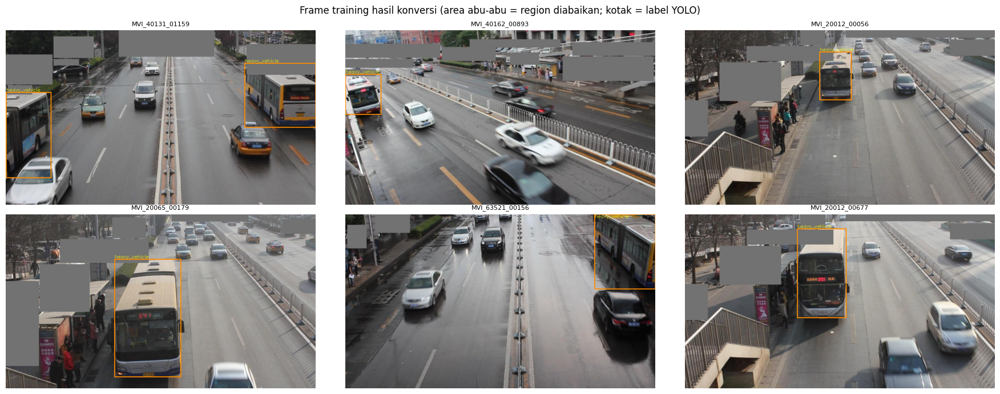

In [ ]:
# Cek visual dari FILE LABEL hasil konversi
def draw_yolo_file(img_path, ax):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lp = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
    for ln in lp.read_text().splitlines():
        c, cx, cy, w, h = ln.split(); c = int(c); cx, cy, w, h = map(float, (cx, cy, w, h))
        x1, y1, x2, y2 = int((cx - w / 2) * W), int((cy - h / 2) * H), int((cx + w / 2) * W), int((cy + h / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 140, 0), 2)
        cv2.putText(img, CLASS_NAMES[c], (x1, max(12, y1 - 3)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1)
    ax.imshow(img); ax.axis("off"); ax.set_title(Path(img_path).stem, fontsize=8)

pos = manifest_df[(manifest_df.split == "train") & (manifest_df.n_labels > 0)].sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, p in zip(axes.ravel(), pos.image):
    draw_yolo_file(p, ax)
plt.suptitle("Frame training hasil konversi (area abu-abu = region diabaikan; kotak = label YOLO)"); plt.tight_layout(); plt.show()

### Persiapan Konfigurasi Dataset YOLO
Kode membuat file `data.yaml` yang berisi lokasi train, validation, test, jumlah kelas, dan nama kelas sebagai konfigurasi untuk Ultralytics.

In [ ]:
# data.yaml
data_yaml = YOLO_DIR / "data.yaml"
data_yaml.write_text(
    f"path: {YOLO_DIR.resolve()}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    f"nc: {len(CLASS_NAMES)}\n"
    "names:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASS_NAMES)))
print(data_yaml.read_text())

path: /kaggle/working/yolo_data
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: heavy_vehicle



### 8. Pelatihan YOLO11m
Kode memuat model awal `yolo11m.pt`, mengatur parameter training, augmentasi, perangkat, dan seed, kemudian melatih model menggunakan konfigurasi dataset YOLO.

In [ ]:
import ultralytics
from ultralytics import YOLO
print("Ultralytics:", ultralytics.__version__)

seed_everything()
RUN_NAME = "yolo11_heavy"
DEVICE = CFG["DEVICE"] if HAS_GPU else "cpu"

train_kw = dict(
    data=str(data_yaml), imgsz=CFG["IMGSZ"], epochs=CFG["EPOCHS"], patience=CFG["PATIENCE"],
    batch=CFG["BATCH"], workers=CFG["WORKERS"], device=DEVICE,
    project=str(RUNS_DIR), name=RUN_NAME, exist_ok=True,
    seed=SEED, deterministic=True, cos_lr=True, close_mosaic=CFG["CLOSE_MOSAIC"], amp=True,
    fliplr=0.5, flipud=0.0, mosaic=1.0, mixup=0.0, scale=0.5, translate=0.1,
    hsv_h=0.015, hsv_s=0.6, hsv_v=0.45, degrees=0.0,
    plots=True, val=True, save=True, cache=False,
)
if CFG["TIME_HOURS"]:
    train_kw["time"] = CFG["TIME_HOURS"]

last_ckpts = sorted(RUNS_DIR.rglob("weights/last.pt"), key=lambda p: p.stat().st_mtime)
if CFG["RESUME"] and last_ckpts:
    print("Melanjutkan training dari:", last_ckpts[-1])
    model = YOLO(str(last_ckpts[-1]))
    model.train(resume=True)
else:
    model = YOLO(CFG["MODEL"])
    model.train(**train_kw)
RUN_DIR = Path(model.trainer.save_dir)
print("Hasil training di:", RUN_DIR)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.216
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=tor

### 9. Pemilihan Bobot Terbaik
Kode membaca hasil training per epoch, menampilkan kurva loss dan metrik validasi, serta mengidentifikasi epoch dengan nilai mAP50-95 validasi tertinggi. Bobot terbaik disimpan oleh proses training sebagai `best.pt`.

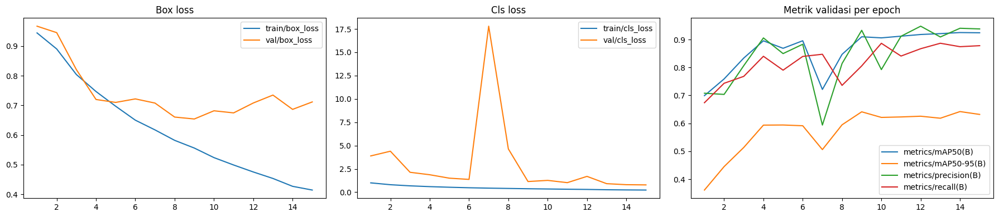

Epoch terbaik (mAP50-95 val): 14 | mAP50=0.9250 | mAP50-95=0.6422


In [ ]:
res = pd.read_csv(RUN_DIR / "results.csv"); res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for c in ["train/box_loss", "val/box_loss"]: ax[0].plot(res.epoch, res[c], label=c)
ax[0].set_title("Box loss"); ax[0].legend()
for c in ["train/cls_loss", "val/cls_loss"]: ax[1].plot(res.epoch, res[c], label=c)
ax[1].set_title("Cls loss"); ax[1].legend()
for c in ["metrics/mAP50(B)", "metrics/mAP50-95(B)", "metrics/precision(B)", "metrics/recall(B)"]: ax[2].plot(res.epoch, res[c], label=c)
ax[2].set_title("Metrik validasi per epoch"); ax[2].legend(); plt.tight_layout(); plt.show()
best_row = res.loc[res["metrics/mAP50-95(B)"].idxmax()]
print(f"Epoch terbaik (mAP50-95 val): {int(best_row.epoch)} | mAP50={best_row['metrics/mAP50(B)']:.4f} | mAP50-95={best_row['metrics/mAP50-95(B)']:.4f}")

### 10. Evaluasi Model pada Data Uji
Kode memuat bobot `best.pt`, lalu mengevaluasi model pada split validation dan test menggunakan precision, recall, mAP50, dan mAP50-95.

In [ ]:
best = YOLO(str(RUN_DIR / "weights" / "best.pt"))

EVAL_DIRS = {}
def run_official(split):
    m = best.val(data=str(data_yaml), split=split, imgsz=CFG["IMGSZ"], batch=CFG["BATCH"],
                 conf=0.001, iou=0.6, plots=True, project=str(RUNS_DIR), name=f"eval_{split}", exist_ok=True,
                 device=0 if HAS_GPU else "cpu")
    EVAL_DIRS[split] = Path(getattr(m, "save_dir", RUNS_DIR / f"eval_{split}"))
    rows = [dict(kelas="SEMUA", P=m.box.mp, R=m.box.mr, mAP50=m.box.map50, mAP50_95=m.box.map)]
    for i, ci in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        rows.append(dict(kelas=CLASS_NAMES[int(ci)], P=p, R=r, mAP50=ap50, mAP50_95=ap))
    return pd.DataFrame(rows).round(4)

official_val  = run_official("val");  print("VALIDASI"); display(official_val)
official_test = run_official("test"); print("TEST");      display(official_test)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2692.7±713.6 MB/s, size: 109.1 KB)
val: Scanning /kaggle/working/yolo_data/labels/val.cache... 1886 images, 1089 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1886/1886 565.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 118/118 1.4it/s 1:250.7ss
                   all       1886       1107      0.954      0.874      0.928      0.637
Speed: 1.1ms preprocess, 41.9ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /kaggle/working/runs/eval_val
VALIDASI


,kelas,P,R,mAP50,mAP50_95
0,SEMUA,0.9544,0.8735,0.9277,0.6373
1,heavy_vehicle,0.9544,0.8735,0.9277,0.6373


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2218.8±842.8 MB/s, size: 127.3 KB)
val: Scanning /kaggle/working/yolo_data/labels/test... 11237 images, 4199 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 11237/11237 1.4Kit/s 8.2s0.1s
val: New cache created: /kaggle/working/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 703/703 1.4it/s 8:290.7ss
                   all      11237      16427      0.872      0.648      0.698      0.484
Speed: 1.1ms preprocess, 41.8ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /kaggle/working/runs/eval_test
TEST


,kelas,P,R,mAP50,mAP50_95
0,SEMUA,0.8722,0.6479,0.6982,0.4838
1,heavy_vehicle,0.8722,0.6479,0.6982,0.4838


### Visualisasi Hasil Evaluasi
Kode menampilkan confusion matrix ternormalisasi, kurva Precision–Recall, dan kurva F1 yang dihasilkan dari evaluasi data test.

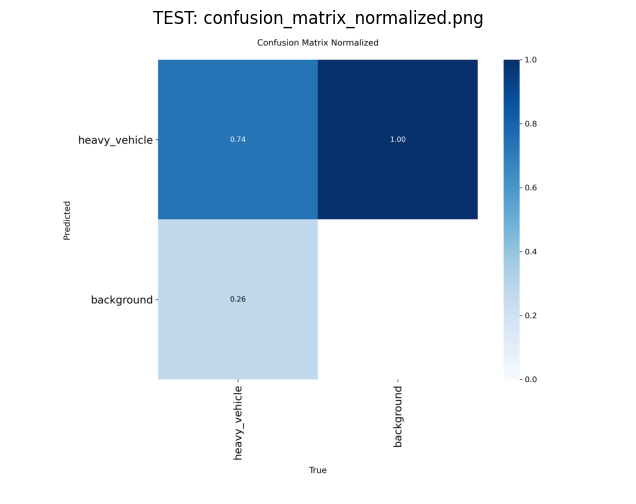

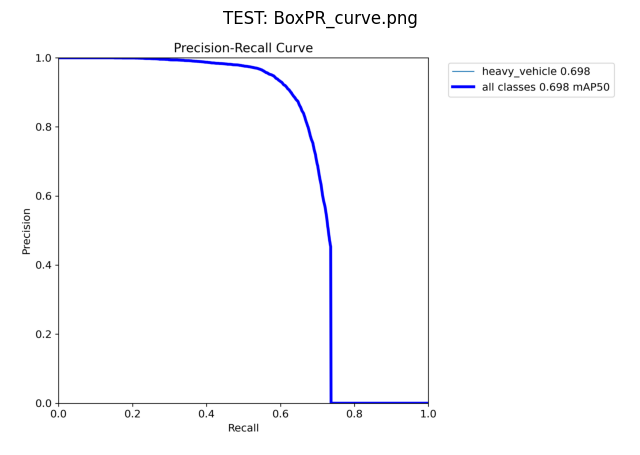

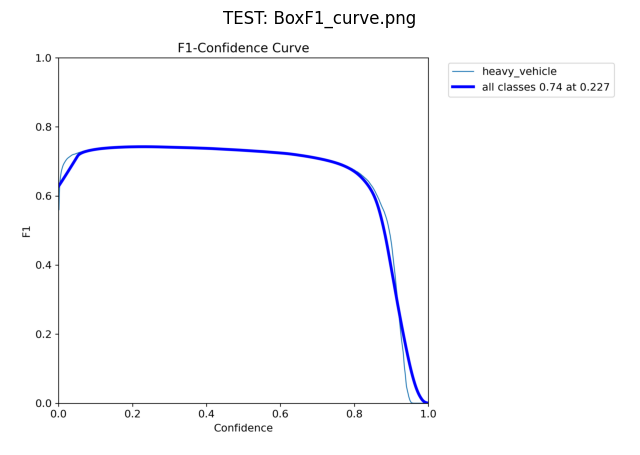

In [ ]:
from PIL import Image
for fn in ["confusion_matrix_normalized.png", "BoxPR_curve.png", "BoxF1_curve.png"]:
    p = EVAL_DIRS.get("test", RUNS_DIR / "eval_test") / fn
    if p.exists():
        plt.figure(figsize=(8, 6)); plt.imshow(Image.open(p)); plt.axis("off"); plt.title(f"TEST: {fn}"); plt.show()

### 11. Penentuan Ambang Confidence
Kode menguji beberapa nilai confidence pada data validation, menghitung precision, recall, dan F1, lalu memilih ambang confidence dengan nilai F1 tertinggi. Data test tidak digunakan untuk memilih ambang.

Ambang confidence terpilih di VALIDASI (F1 maksimum): 0.45


,conf,TP,FP,FN,precision,recall,F1
16,0.45,974,48,133,0.953,0.8799,0.915


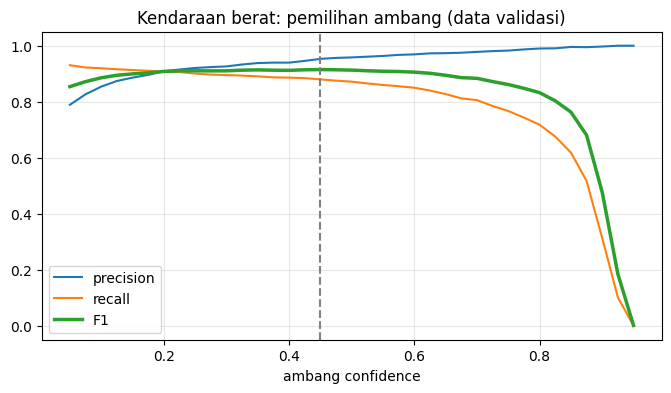

In [ ]:
IOU_MATCH = 0.5

def read_gt(img_path):
    lp = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
    H, W = cv2.imread(str(img_path)).shape[:2]
    rows = []
    for ln in lp.read_text().splitlines():
        c, cx, cy, w, h = ln.split(); c = int(c); cx, cy, w, h = map(float, (cx, cy, w, h))
        rows.append([c, (cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H])
    return np.array(rows, dtype=np.float32).reshape(-1, 5)

def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def collect_predictions(mdl, split, chunk=128):
    paths = sorted((YOLO_DIR / "images" / split).glob("*.jpg"))
    recs = []
    for i in range(0, len(paths), chunk):
        part = [str(p) for p in paths[i:i + chunk]]
        for p, r in zip(part, mdl.predict(part, imgsz=CFG["IMGSZ"], conf=0.001, iou=0.6, verbose=False,
                                          quantize=16 if HAS_GPU else 32, device=0 if HAS_GPU else "cpu", stream=False)):
            bx = r.boxes
            recs.append(dict(path=p, gt=read_gt(p),
                             pred=np.concatenate([bx.cls.cpu().numpy().reshape(-1, 1),
                                                   bx.conf.cpu().numpy().reshape(-1, 1),
                                                   bx.xyxy.cpu().numpy().reshape(-1, 4)], axis=1)
                             if len(bx) else np.zeros((0, 6), dtype=np.float32)))
    return recs

def match_record(rec, thr):
    gt, pr = rec["gt"], rec["pred"]
    pr = pr[pr[:, 1] >= thr]
    pr = pr[np.argsort(-pr[:, 1])]
    gt_hit = np.zeros(len(gt), dtype=bool); pred_tp = np.zeros(len(pr), dtype=bool)
    if len(pr) and len(gt):
        ious = iou_matrix(pr[:, 2:6], gt[:, 1:5])
        for i in range(len(pr)):
            cand = ious[i].copy()
            cand[(gt[:, 0] != pr[i, 0]) | gt_hit] = -1
            j = int(np.argmax(cand))
            if cand[j] >= IOU_MATCH:
                gt_hit[j] = True; pred_tp[i] = True
    return pr, pred_tp, gt_hit

def prf_at(recs, thr, classes=None):
    tp = fp = fn = 0
    for rec in recs:
        pr, ptp, ghit = match_record(rec, thr)
        gt = rec["gt"]
        if classes is not None:
            pm = np.isin(pr[:, 0], classes); gm = np.isin(gt[:, 0], classes)
            ptp, ghit = ptp[pm], ghit[gm]
        tp += ptp.sum(); fp += (~ptp).sum(); fn += (~ghit).sum()
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return dict(TP=int(tp), FP=int(fp), FN=int(fn), precision=p, recall=r, F1=f1)

val_recs = collect_predictions(best, "val")
grid = np.round(np.arange(0.05, 0.951, 0.025), 3)
sweep = pd.DataFrame([dict(conf=t, **prf_at(val_recs, t, HEAVY_IDS)) for t in grid])
BEST_CONF = float(sweep.loc[sweep.F1.idxmax(), "conf"])
print(f"Ambang confidence terpilih di VALIDASI (F1 maksimum): {BEST_CONF}")
display(sweep.loc[sweep.F1.idxmax():sweep.F1.idxmax()].round(4))

plt.figure(figsize=(8, 4))
plt.plot(sweep.conf, sweep.precision, label="precision"); plt.plot(sweep.conf, sweep.recall, label="recall")
plt.plot(sweep.conf, sweep.F1, label="F1", lw=2.5); plt.axvline(BEST_CONF, ls="--", c="gray")
plt.xlabel("ambang confidence"); plt.title("Kendaraan berat: pemilihan ambang (data validasi)"); plt.legend(); plt.grid(alpha=.3); plt.show()

### Evaluasi Akhir pada Data Uji
Dengan ambang confidence terpilih, kode menghitung TP, FP, FN, precision, recall, dan F1 pada tingkat objek serta metrik klasifikasi keberadaan kendaraan berat pada tingkat frame.

TEST | tingkat objek, kendaraan berat, IoU 0.5, conf = 0.45


,TP,FP,FN,precision,recall,F1
0,10193,1026,6234,0.9085,0.6205,0.7374


TEST | tingkat frame (ada kendaraan berat atau tidak):


,frame_total,frame_positif,akurasi,presisi,recall,spesifisitas,F1
0,11237,7038,0.8421,0.9647,0.7764,0.9524,0.8603


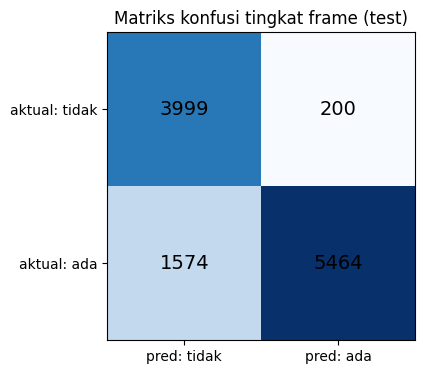

In [ ]:
test_recs = collect_predictions(best, "test")

# --- tingkat objek
obj_all = prf_at(test_recs, BEST_CONF, HEAVY_IDS)
print("TEST | tingkat objek, kendaraan berat, IoU 0.5, conf =", BEST_CONF)
display(pd.DataFrame([obj_all]).round(4))
if CFG["CLASS_MODE"] == "four_class":
    per = [dict(kelas=CLASS_NAMES[c], **prf_at(test_recs, BEST_CONF, [c])) for c in range(len(CLASS_NAMES))]
    display(pd.DataFrame(per).round(4))

# --- tingkat frame
def frame_flags(recs, thr, classes):
    y, yhat = [], []
    for rec in recs:
        y.append(bool(np.isin(rec["gt"][:, 0], classes).any()))
        pr = rec["pred"]; pr = pr[pr[:, 1] >= thr]
        yhat.append(bool(np.isin(pr[:, 0], classes).any()))
    return np.array(y), np.array(yhat)

y, yh = frame_flags(test_recs, BEST_CONF, HEAVY_IDS)
tp = int((y & yh).sum()); tn = int((~y & ~yh).sum()); fp_ = int((~y & yh).sum()); fn_ = int((y & ~yh).sum())
acc = (tp + tn) / len(y); prec = tp / max(tp + fp_, 1); rec_ = tp / max(tp + fn_, 1)
spec = tn / max(tn + fp_, 1); f1 = 2 * prec * rec_ / max(prec + rec_, 1e-9)
frame_metrics = dict(frame_total=len(y), frame_positif=int(y.sum()), akurasi=acc, presisi=prec, recall=rec_, spesifisitas=spec, F1=f1)
print("TEST | tingkat frame (ada kendaraan berat atau tidak):")
display(pd.DataFrame([frame_metrics]).round(4))

cm = np.array([[tn, fp_], [fn_, tp]])
plt.figure(figsize=(4.5, 4)); plt.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): plt.text(j, i, f"{v}", ha="center", va="center", fontsize=14)
plt.xticks([0, 1], ["pred: tidak", "pred: ada"]); plt.yticks([0, 1], ["aktual: tidak", "aktual: ada"])
plt.title("Matriks konfusi tingkat frame (test)"); plt.show()

### 12. Analisis Kondisi Lingkungan dan Skala Objek
Kode mengelompokkan hasil deteksi berdasarkan cuaca dan ukuran objek (kecil, sedang, besar), kemudian membandingkan precision, recall, dan F1 untuk melihat kondisi yang memengaruhi kinerja model.

In [ ]:
def seq_of(path):
    return Path(path).stem.rsplit("_", 1)[0]

rows_w, rows_s, rows_seq = [], [], []
for rec in test_recs:
    sq = seq_of(rec["path"]); wth = seq_df.loc[sq, "weather"]
    pr, ptp, ghit = match_record(rec, BEST_CONF)
    gt = rec["gt"]
    hm = np.isin(gt[:, 0], HEAVY_IDS); pm = np.isin(pr[:, 0], HEAVY_IDS)
    for k in np.where(hm)[0]:
        sc = float(np.sqrt((gt[k, 3] - gt[k, 1]) * (gt[k, 4] - gt[k, 2])))
        rows_s.append(dict(skala="kecil(<50)" if sc < 50 else ("sedang(50-150)" if sc < 150 else "besar(>150)"), hit=bool(ghit[k])))
    rows_w.append(dict(cuaca=wth, seq=sq, TP=int(ptp[pm].sum()), FP=int((~ptp[pm]).sum()), FN=int((~ghit[hm]).sum())))

def agg(df, key):
    g = df.groupby(key)[["TP", "FP", "FN"]].sum()
    g["precision"] = g.TP / (g.TP + g.FP).clip(lower=1)
    g["recall"] = g.TP / (g.TP + g.FN).clip(lower=1)
    g["F1"] = 2 * g.precision * g.recall / (g.precision + g.recall).clip(lower=1e-9)
    g["jumlah_GT"] = g.TP + g.FN
    return g.round(4)

det_df = pd.DataFrame(rows_w)
print("Per cuaca:"); display(agg(det_df, "cuaca"))
sc_df = pd.DataFrame(rows_s)
if len(sc_df):
    print("Recall per ukuran objek GT (kendaraan berat):")
    display(sc_df.groupby("skala").hit.agg(recall="mean", jumlah_GT="size").round(4))
print("Sekuens dengan F1 terendah (hanya yang punya GT kendaraan berat di frame sampel):")
per_seq = agg(det_df, "seq")
display(per_seq[per_seq.jumlah_GT > 0].sort_values("F1").head(8))

Per cuaca:


,TP,FP,FN,precision,recall,F1,jumlah_GT
cuaca,,,,,,,
cloudy,2096,202,1445,0.9121,0.5919,0.7179,3541
night,3219,305,1258,0.9135,0.7190,0.8046,4477
rainy,3534,326,3302,0.9155,0.5170,0.6608,6836
sunny,1344,193,229,0.8744,0.8544,0.8643,1573


Recall per ukuran objek GT (kendaraan berat):


,recall,jumlah_GT
skala,,
besar(>150),0.7264,6496
kecil(<50),0.1005,408
sedang(50-150),0.5705,9523


Sekuens dengan F1 terendah (hanya yang punya GT kendaraan berat di frame sampel):


,TP,FP,FN,precision,recall,F1,jumlah_GT
seq,,,,,,,
MVI_40792,0,1,15,0.0000,0.0000,0.0000,15
MVI_40763,11,8,159,0.5789,0.0647,0.1164,170
MVI_40905,39,82,446,0.3223,0.0804,0.1287,485
MVI_40761,49,90,452,0.3525,0.0978,0.1531,501
MVI_40901,47,102,278,0.3154,0.1446,0.1983,325
MVI_40891,52,6,363,0.8966,0.1253,0.2199,415
MVI_39361,19,96,1,0.1652,0.9500,0.2815,20
MVI_40904,78,10,312,0.8864,0.2000,0.3264,390


### Analisis Kesalahan Deteksi
Kode menampilkan contoh frame dengan false negative (kendaraan terlewat) dan false positive (deteksi keliru) untuk membantu pemeriksaan visual hasil model.

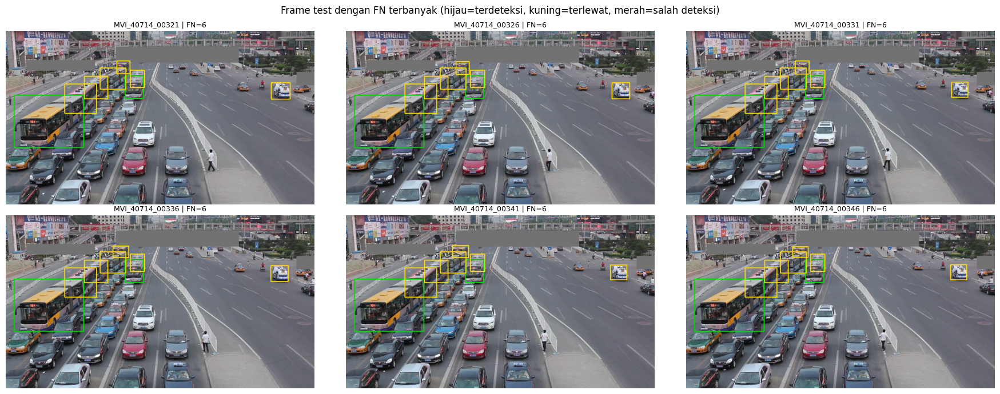

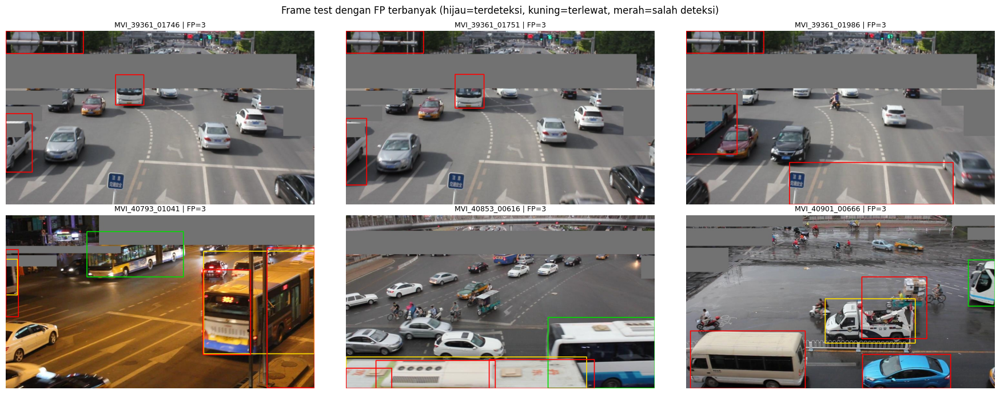

In [ ]:
def show_errors(recs, thr, n=6, by="FN"):
    scored = []
    for rec in recs:
        pr, ptp, ghit = match_record(rec, thr)
        gt = rec["gt"]; hm = np.isin(gt[:, 0], HEAVY_IDS); pm = np.isin(pr[:, 0], HEAVY_IDS)
        fn = int((~ghit[hm]).sum()); fp = int((~ptp[pm]).sum())
        scored.append((fn if by == "FN" else fp, rec, pr, ptp, ghit))
    scored.sort(key=lambda x: -x[0])
    fig, axes = plt.subplots(2, 3, figsize=(18, 7))
    for ax, (cnt, rec, pr, ptp, ghit) in zip(axes.ravel(), scored[:n]):
        img = cv2.cvtColor(cv2.imread(rec["path"]), cv2.COLOR_BGR2RGB)
        for k, g in enumerate(rec["gt"]):
            if g[0] not in HEAVY_IDS: continue
            col = (0, 220, 0) if ghit[k] else (255, 220, 0)
            cv2.rectangle(img, (int(g[1]), int(g[2])), (int(g[3]), int(g[4])), col, 2)
        for k, p in enumerate(pr):
            if p[0] in HEAVY_IDS and not ptp[k]:
                cv2.rectangle(img, (int(p[2]), int(p[3])), (int(p[4]), int(p[5])), (255, 0, 0), 2)
        ax.imshow(img); ax.axis("off"); ax.set_title(f"{Path(rec['path']).stem} | {by}={cnt}", fontsize=9)
    plt.suptitle(f"Frame test dengan {by} terbanyak (hijau=terdeteksi, kuning=terlewat, merah=salah deteksi)"); plt.tight_layout(); plt.show()

show_errors(test_recs, BEST_CONF, by="FN")
show_errors(test_recs, BEST_CONF, by="FP")

In [ ]:
import logging
import shutil
import subprocess
import base64
from tempfile import TemporaryDirectory

from IPython.display import HTML, display
from tqdm.auto import tqdm
from ultralytics.utils import LOGGER


class _FilterHalfDemo(logging.Filter):
    def filter(self, record):
        msg = record.getMessage()
        return not ("'half' is deprecated" in msg and "'quantize'" in msg)


demo_seq = seq_df[seq_df.split == "test"].sort_values(
    "n_heavy", ascending=False
).index[0]
nums = sorted(frame_maps[demo_seq])[::2]

OUT_DIR.mkdir(parents=True, exist_ok=True)
vpath = OUT_DIR / f"demo_{demo_seq}.mp4"

if not nums:
    raise RuntimeError(f"Tidak ada frame untuk sekuens {demo_seq}")

fps_output = 12
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
vw = cv2.VideoWriter(str(vpath), fourcc, fps_output, (IMG_W, IMG_H))
if not vw.isOpened():
    raise RuntimeError(f"VideoWriter gagal dibuka: {vpath}")

precision = 16 if HAS_GPU else 32
frames_written = 0

_filter_half_demo = _FilterHalfDemo()
LOGGER.addFilter(_filter_half_demo)
try:
    for n in tqdm(nums, desc=f"Membuat video {demo_seq}", unit="frame"):
        img = cv2.imread(str(frame_maps[demo_seq][n]))
        if img is None:
            print(f"Frame tidak dapat dibaca dan dilewati: {n}")
            continue

        if img.shape[:2] != (IMG_H, IMG_W):
            raise ValueError(
                f"Ukuran frame {n} = {img.shape[:2]}, "
                f"tetapi VideoWriter membutuhkan {(IMG_H, IMG_W)}"
            )

        img[ignore_masks[demo_seq]] = CFG["FILL_VALUE"]

        result = best.predict(
            img,
            imgsz=CFG["IMGSZ"],
            conf=BEST_CONF,
            iou=0.6,
            verbose=False,
            quantize=precision,
        )[0]

        for b in result.boxes:
            x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
            cls_id = int(b.cls.item())
            conf = float(b.conf.item())
            label = f"{CLASS_NAMES[cls_id]} {conf:.2f}"
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 140, 255), 2)
            cv2.putText(
                img, label, (x1, max(14, y1 - 4)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 2
            )

        vw.write(img)
        frames_written += 1
finally:
    LOGGER.removeFilter(_filter_half_demo)
    vw.release()

if frames_written == 0:
    raise RuntimeError("Tidak ada frame yang berhasil ditulis ke video")

ffmpeg = shutil.which("ffmpeg")
if ffmpeg is None:
    from imageio_ffmpeg import get_ffmpeg_exe
    ffmpeg = get_ffmpeg_exe()

with TemporaryDirectory(dir=vpath.parent) as temp_dir:
    siap_putar = Path(temp_dir) / "demo.mp4"
    subprocess.run(
        [ffmpeg, "-nostdin", "-hide_banner", "-loglevel", "error",
         "-i", str(vpath),
         "-an", "-c:v", "libx264", "-preset", "fast", "-crf", "23",
         "-pix_fmt", "yuv420p", "-movflags", "+faststart",
         str(siap_putar)],
        check=True,
    )
    siap_putar.replace(vpath)

print(f"Video demo : {vpath}")
print(f"Frames     : {frames_written}")
print(f"Durasi     : {frames_written / fps_output:.1f} detik")
print(f"Ukuran     : {vpath.stat().st_size / (1024**2):.2f} MB")

video_base64 = base64.b64encode(vpath.read_bytes()).decode("ascii")

display(HTML(f"""
<video width="720" controls playsinline preload="metadata">
    <source src="data:video/mp4;base64,{video_base64}"
            type="video/mp4">
    Your browser does not support HTML5 video.
</video>
"""))


Membuat video MVI_40863:   0%|          | 0/835 [00:00<?, ?frame/s]

Video demo : /kaggle/working/hasil/demo_MVI_40863.mp4
Frames     : 835
Durasi     : 69.6 detik
Ukuran     : 8.91 MB


In [ ]:
final = dict(
    config={k: v for k, v in CFG.items()},
    kelas=CLASS_NAMES, ambang_confidence=BEST_CONF, iou_pencocokan=IOU_MATCH,
    objek_test=obj_all, frame_test=frame_metrics,
    resmi_val=official_val.to_dict("records") if "official_val" in globals() else None,
    resmi_test=official_test.to_dict("records") if "official_test" in globals() else None,
    waktu_training_jam=CFG["TIME_HOURS"], epoch_dikonfigurasi=CFG["EPOCHS"],
    jumlah_sekuens=seq_df.split.value_counts().to_dict(),
)
(OUT_DIR / "metrik_akhir.json").write_text(json.dumps(final, indent=2, default=float))

if "RUN_DIR" in globals():
    shutil.copy(RUN_DIR / "weights" / "best.pt", OUT_DIR / "best.pt")
    for f in ["results.csv", "results.png"]:
        if (RUN_DIR / f).exists(): shutil.copy(RUN_DIR / f, OUT_DIR / f)
    for sp in ["val", "test"]:
        d = EVAL_DIRS.get(sp, RUNS_DIR / f"eval_{sp}")
        if d.exists(): shutil.copytree(d, OUT_DIR / f"eval_{sp}", dirs_exist_ok=True)
    if CFG["EXPORT_ONNX"]:
        best.export(format="onnx", imgsz=CFG["IMGSZ"], dynamic=False, simplify=True)

zip_path = shutil.make_archive(str(WORK / "hasil_yolo11_kendaraan_berat"), "zip", OUT_DIR)
print("Paket hasil:", zip_path)
print(json.dumps({"ambang": BEST_CONF, "objek_test": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in obj_all.items()},
                  "frame_test": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in frame_metrics.items()}}, indent=2))

Paket hasil: /kaggle/working/hasil_yolo11_kendaraan_berat.zip
{
  "ambang": 0.45,
  "objek_test": {
    "TP": 10193,
    "FP": 1026,
    "FN": 6234,
    "precision": 0.9085,
    "recall": 0.6205,
    "F1": 0.7374
  },
  "frame_test": {
    "frame_total": 11237,
    "frame_positif": 7038,
    "akurasi": 0.8421,
    "presisi": 0.9647,
    "recall": 0.7764,
    "spesifisitas": 0.9524,
    "F1": 0.8603
  }
}
